In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [5]:
train = tf.keras.utils.image_dataset_from_directory(
    'cats_vs_dogs',
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='training',
    seed=123
)

val = tf.keras.utils.image_dataset_from_directory(
    'cats_vs_dogs',
    image_size=(224,224),
    batch_size=32,
    validation_split=0.2,
    subset='validation',
    seed=123
)

Found 1000 files belonging to 2 classes.
Using 800 files for training.
Found 1000 files belonging to 2 classes.
Using 200 files for validation.


In [7]:
base_model = tf.keras.applications.ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 17s 0us/step


In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Rescaling(1./255),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(2, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [10]:
h1 = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 118s 4s/step - accuracy: 0.4900 - loss: 0.8000 - val_accuracy: 0.4350 - val_loss: 0.8222
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 103s 4s/step - accuracy: 0.5113 - loss: 0.7147 - val_accuracy: 0.4350 - val_loss: 0.8194
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 113s 5s/step - accuracy: 0.5138 - loss: 0.7055 - val_accuracy: 0.4350 - val_loss: 0.7297


In [ ]:
base_model.trainable = True

for layer in base_model.layers[:-10]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

h2 = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 137s 5s/step - accuracy: 0.6025 - loss: 0.6790 - val_accuracy: 0.4350 - val_loss: 0.7431
Epoch 2/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.6850 - loss: 0.5955 - val_accuracy: 0.6550 - val_loss: 0.6555
Epoch 3/3
25/25 ━━━━━━━━━━━━━━━━━━━━ 140s 4s/step - accuracy: 0.7025 - loss: 0.5559 - val_accuracy: 0.6050 - val_loss: 0.6719


Before Fine Tuning: 0.4350000023841858
After Fine Tuning: 0.6050000190734863


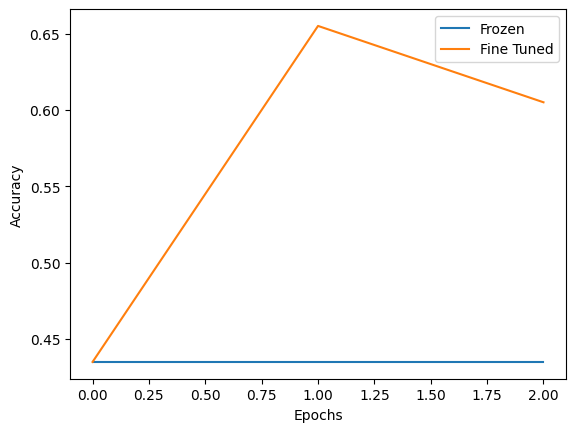

In [14]:
print("Before Fine Tuning:", h1.history['val_accuracy'][-1])
print("After Fine Tuning:", h2.history['val_accuracy'][-1])

plt.plot(h1.history['val_accuracy'], label='Frozen')
plt.plot(h2.history['val_accuracy'], label='Fine Tuned')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()